# 01 - Train Video Stroke Classifier (RGB)

Runs on **Google Colab with a T4 GPU**. Run each cell top to bottom.

Trains a TemporalPoolingResNet on the 5 shots (Short Serve, Lift, Clear, Drop Shot, Smash) and saves the model + label mapping + metrics + confusion matrix to Drive.

In [23]:
import torch, os
assert torch.cuda.is_available(), 'No GPU active. In Colab: Runtime > Change runtime type > T4 GPU, then re-run this cell.'
print('GPU:', torch.cuda.get_device_name(0))
from google.colab import drive
if not os.path.isdir('/content/drive/MyDrive'):
    drive.mount('/content/drive')
print('Drive ready:', os.path.isdir('/content/drive/MyDrive'))
!pip install -q opencv-python-headless tqdm seaborn

GPU: NVIDIA L4
Drive ready: True


In [24]:
CLASSES = [
    (0, 'Short Serve', '00_Short Serve'),
    (1, 'Lift',        '02_Lift'),
    (2, 'Clear',       '12_Clear'),
    (3, 'Drop Shot',   '05_Drop Shot'),
    (4, 'Smash',       '14_Smash'),
]
NUM_CLASSES   = len(CLASSES)
DISPLAY_NAMES = [c[1] for c in CLASSES]
CLASS_FOLDERS = [c[2] for c in CLASSES]
ID_TO_NAME    = {c[0]: c[1] for c in CLASSES}
FOLDER_TO_ID  = {c[2]: c[0] for c in CLASSES}
PAD_TOKEN     = NUM_CLASSES

DRIVE       = '/content/drive/MyDrive/BadmintonFYP'
MODELS      = DRIVE + '/model23'
DATASET_ZIP = DRIVE + '/DATASET2.zip'
DATASET_DIR = '/content/Dataset'

NUM_FRAMES = 16 
IMG        = 224
BATCH      = 8
EPOCHS     = 15
LR         = 1e-4
SEED       = 42
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

import os
os.makedirs(MODELS, exist_ok=True)
print('Classes:', DISPLAY_NAMES)
print('Models dir:', MODELS)

Classes: ['Short Serve', 'Lift', 'Clear', 'Drop Shot', 'Smash']
Models dir: /content/drive/MyDrive/BadmintonFYP/model23


In [25]:
import os, json, glob, zipfile, shutil
import cv2
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision.models as models
import torchvision.transforms as transforms
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)

from google.colab import drive
if not os.path.isdir('/content/drive/MyDrive'):
    drive.mount('/content/drive')
print('Drive mounted:', os.path.isdir('/content/drive/MyDrive'))

EXTRACT_DIR    = '/content/data'
GDRIVE_FILE_ID = ''

def has_all(d):
    return os.path.isdir(d) and all(os.path.isdir(os.path.join(d, f)) for f in CLASS_FOLDERS)
def find_root(base):
    for c in [base] + sorted(glob.glob(base + '/*')) + sorted(glob.glob(base + '/*/*')):
        if os.path.isdir(c) and any(os.path.isdir(os.path.join(c, f)) for f in CLASS_FOLDERS):
            return c
    return None

root = find_root(EXTRACT_DIR)
if root is None or not has_all(root):
    zips = []
    for pat in (DATASET_ZIP, DRIVE + '/*.zip', '/content/drive/MyDrive/*.zip',
                '/content/drive/MyDrive/**/*.zip', '/content/*.zip'):
        zips += glob.glob(pat, recursive=True)
    zips = sorted(set(z for z in zips if os.path.exists(z)), key=lambda z: (0 if 'dataset' in z.lower() else 1, len(z)))

   
    if not zips:
        try:
            import gdown
            out = '/content/DATASET2.zip'
            if not os.path.exists(out):
                print('No local zip - downloading DATASET2.zip by file ID via gdown...')
                gdown.download(id=GDRIVE_FILE_ID, output=out, quiet=False)
            if os.path.exists(out) and os.path.getsize(out) > 1_000_000:
                zips = [out]
            else:
                print('Download did not produce a valid zip - check the file sharing is "Anyone with the link".')
        except Exception as e:
            print('gdown download failed:', e)

   
    if zips:
        print('Extracting', zips[0], 'to', EXTRACT_DIR, '(one-time)...')
        if os.path.exists(EXTRACT_DIR): shutil.rmtree(EXTRACT_DIR)
        with zipfile.ZipFile(zips[0]) as z:
            z.extractall(EXTRACT_DIR)
        root = find_root(EXTRACT_DIR)
        print('Extracted.')

if root is None:
    for d in sorted(glob.glob(DRIVE + '/*')) + sorted(glob.glob('/content/drive/MyDrive/*')):
        if find_root(d): root = find_root(d); break

DATASET_DIR = root or EXTRACT_DIR
print('Using DATASET_DIR =', DATASET_DIR)

if os.path.isdir(DATASET_DIR):
    subs = sorted([d for d in os.listdir(DATASET_DIR) if os.path.isdir(os.path.join(DATASET_DIR, d))])
    print('Subfolders found:', subs)
    for f in CLASS_FOLDERS:
        p = os.path.join(DATASET_DIR, f)
        n = len(glob.glob(p + '/*.mp4')) if os.path.isdir(p) else 'MISSING'
        print('  ', f, '->', n)

Device: cuda
Drive mounted: True
Using DATASET_DIR = /content/data
Subfolders found: ['00_Short Serve', '02_Lift', '05_Drop Shot', '12_Clear', '14_Smash']
   00_Short Serve -> 881
   02_Lift -> 758
   12_Clear -> 945
   05_Drop Shot -> 812
   14_Smash -> 822


In [26]:
def load_video_frames(path, num_frames=NUM_FRAMES):
    cap = cv2.VideoCapture(path)
    if not cap.isOpened():
        raise ValueError('cannot open ' + path)
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    if total == 0:
        cap.release(); raise ValueError('0 frames ' + path)
    idxs = np.linspace(0, total - 1, num_frames, dtype=int)
    frames = []
    for i in idxs:
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
        ok, fr = cap.read()
        if ok:
            frames.append(cv2.cvtColor(fr, cv2.COLOR_BGR2RGB))
        elif frames:
            frames.append(frames[-1].copy())
    cap.release()
    while len(frames) < num_frames:
        frames.append(frames[-1].copy() if frames else np.zeros((IMG, IMG, 3), np.uint8))
    return frames[:num_frames]

def letterbox(img, size=IMG):
    h, w = img.shape[:2]
    s = min(size / h, size / w)
    nh, nw = int(h * s), int(w * s)
    r = cv2.resize(img, (nw, nh))
    canvas = np.zeros((size, size, 3), np.uint8)
    y, x = (size - nh) // 2, (size - nw) // 2
    canvas[y:y+nh, x:x+nw] = r
    return canvas

_norm = transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
def preprocess_frames(frames, size=IMG):
    out = []
    for fr in frames:
        fr = letterbox(fr, size).astype(np.float32) / 255.0
        out.append(_norm(torch.from_numpy(fr).permute(2, 0, 1)))
    return torch.stack(out)

class VideoClipDataset(Dataset):
    def __init__(self, df): self.df = df.reset_index(drop=True)
    def __len__(self): return len(self.df)
    def __getitem__(self, i):
        row = self.df.iloc[i]
        try:
            return preprocess_frames(load_video_frames(row.file_path)), int(row.label_id)
        except Exception as e:
            print('skip', row.file_path, e)
            return torch.zeros(NUM_FRAMES, 3, IMG, IMG), int(row.label_id)

def build_index(root):
    rows = []
    for folder in CLASS_FOLDERS:
        p = os.path.join(root, folder)
        if not os.path.isdir(p):
            print('missing folder', p); continue
        lid = FOLDER_TO_ID[folder]
        for fn in os.listdir(p):
            if fn.lower().endswith('.mp4'):
                gid = fn.split('_dataset_set')[0] if '_dataset_set' in fn else fn[:19]
                rows.append({'file_path': os.path.join(p, fn), 'label_id': lid, 'label_name': folder, 'group_id': gid})
    return pd.DataFrame(rows)

def group_split(df, val=0.15, test=0.15, seed=SEED):
    g1 = GroupShuffleSplit(n_splits=1, test_size=val + test, random_state=seed)
    tr, tmp = next(g1.split(df, groups=df.group_id))
    dtr, dtmp = df.iloc[tr].reset_index(drop=True), df.iloc[tmp].reset_index(drop=True)
    g2 = GroupShuffleSplit(n_splits=1, test_size=test / (val + test), random_state=seed)
    va, te = next(g2.split(dtmp, groups=dtmp.group_id))
    dva, dte = dtmp.iloc[va].reset_index(drop=True), dtmp.iloc[te].reset_index(drop=True)
    assert not (set(dtr.group_id) & set(dva.group_id)) and not (set(dtr.group_id) & set(dte.group_id))
    return dtr, dva, dte

class TemporalPoolingResNet(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES, pretrained=True):
        super().__init__()
        w = models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
        base = models.resnet18(weights=w)
        self.features = nn.Sequential(*list(base.children())[:-1])
        self.fc = nn.Linear(512, num_classes)
    def forward(self, x):
        b, t, c, h, w = x.shape
        x = x.view(b * t, c, h, w)
        x = self.features(x).view(b, t, 512).mean(dim=1)
        return self.fc(x)

def class_weights(dtr):
    cnt = dtr.label_id.value_counts().sort_index(); tot = len(dtr)
    return torch.tensor([tot / (NUM_CLASSES * cnt.get(i, 1)) for i in range(NUM_CLASSES)], dtype=torch.float32)

def run_epoch(model, loader, crit, opt=None):
    train = opt is not None
    model.train() if train else model.eval()
    tot, P, L = 0.0, [], []
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            if train: opt.zero_grad()
            out = model(x); loss = crit(out, y)
            if train: loss.backward(); opt.step()
            tot += loss.item() * x.size(0)
            P += out.argmax(1).cpu().tolist(); L += y.cpu().tolist()
    return tot / len(loader.dataset), accuracy_score(L, P), f1_score(L, P, average='macro'), P, L

print('defs ready')

defs ready


In [27]:
df = build_index(DATASET_DIR)
assert len(df) > 0, 'No clips found. Check DATASET_DIR and that folder names match CLASS_FOLDERS.'
print('Total clips:', len(df), '| matches:', df.group_id.nunique())
print(df.label_name.value_counts())
df_train, df_val, df_test = group_split(df)
print('train', len(df_train), 'val', len(df_val), 'test', len(df_test))

Total clips: 4218 | matches: 51
label_name
12_Clear          945
00_Short Serve    881
14_Smash          822
05_Drop Shot      812
02_Lift           758
Name: count, dtype: int64
train 2828 val 658 test 732


In [28]:
WARM_START = True
EPOCHS_RUN = 10          
CKPT = MODELS + '/video_model.pth'

train_loader = DataLoader(VideoClipDataset(df_train), batch_size=BATCH, shuffle=True, num_workers=2)
val_loader   = DataLoader(VideoClipDataset(df_val),   batch_size=BATCH, num_workers=2)
test_loader  = DataLoader(VideoClipDataset(df_test),  batch_size=BATCH, num_workers=2)

model = TemporalPoolingResNet().to(DEVICE)
if WARM_START and os.path.exists(CKPT):
    model.load_state_dict(torch.load(CKPT, map_location=DEVICE))
    print('Warm-start: loaded your existing model (keeps the 4 shots), folding in Clear on all 5 classes')
else:
    print('No checkpoint found - training from scratch on all 5 classes for', EPOCHS_RUN, 'epochs')

crit = nn.CrossEntropyLoss(weight=class_weights(df_train).to(DEVICE))
opt = optim.Adam(model.parameters(), lr=LR)

best_f1, patience, bad = 0.0, 4, 0
for ep in range(EPOCHS_RUN):
    tl, ta, tf, _, _ = run_epoch(model, train_loader, crit, opt)
    vl, va, vf, _, _ = run_epoch(model, val_loader, crit)
    print('epoch', ep + 1, 'train_f1 %.3f' % tf, 'val_f1 %.3f' % vf, 'val_acc %.3f' % va)
    if vf > best_f1:
        best_f1, bad = vf, 0
        torch.save(model.state_dict(), CKPT); print('  saved best %.3f' % vf)
    else:
        bad += 1
        if bad >= patience:
            print('early stop'); break
model.load_state_dict(torch.load(CKPT, map_location=DEVICE))
print('best val macro-F1 %.3f' % best_f1)

No checkpoint found - training from scratch on all 5 classes for 10 epochs
skip /content/data/00_Short Serve/2022-08-31_18-50-39_dataset_set1_004_001116_001116_A_00.mp4 cannot open /content/data/00_Short Serve/2022-08-31_18-50-39_dataset_set1_004_001116_001116_A_00.mp4
epoch 1 train_f1 0.661 val_f1 0.839 val_acc 0.834
  saved best 0.839
skip /content/data/00_Short Serve/2022-08-31_18-50-39_dataset_set1_004_001116_001116_A_00.mp4 cannot open /content/data/00_Short Serve/2022-08-31_18-50-39_dataset_set1_004_001116_001116_A_00.mp4
epoch 2 train_f1 0.843 val_f1 0.882 val_acc 0.880
  saved best 0.882
skip /content/data/00_Short Serve/2022-08-31_18-50-39_dataset_set1_004_001116_001116_A_00.mp4 cannot open /content/data/00_Short Serve/2022-08-31_18-50-39_dataset_set1_004_001116_001116_A_00.mp4
epoch 3 train_f1 0.893 val_f1 0.826 val_acc 0.834
skip /content/data/00_Short Serve/2022-08-31_18-50-39_dataset_set1_004_001116_001116_A_00.mp4 cannot open /content/data/00_Short Serve/2022-08-31_18-50-

TEST acc 0.9508 macro-F1 0.9474
              precision    recall  f1-score   support

 Short Serve       1.00      0.99      0.99       190
        Lift       0.98      0.87      0.92       152
       Clear       0.85      0.98      0.91       130
   Drop Shot       0.97      0.96      0.97       155
       Smash       0.94      0.95      0.95       105

    accuracy                           0.95       732
   macro avg       0.95      0.95      0.95       732
weighted avg       0.95      0.95      0.95       732



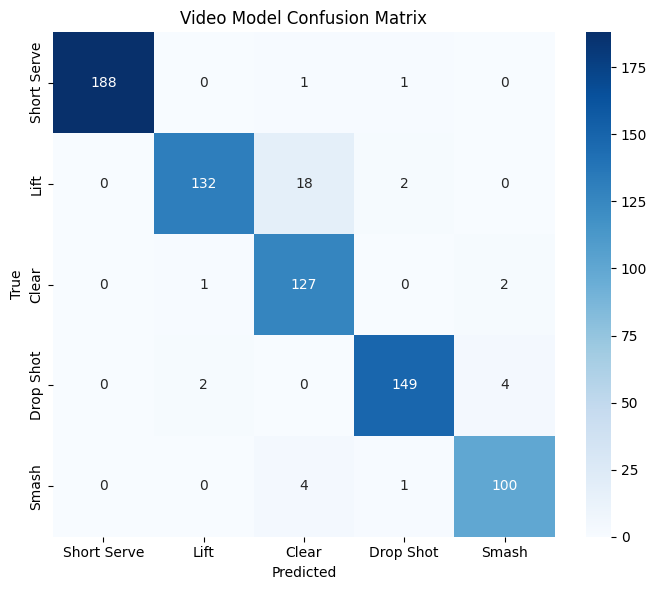

Saved model + label_mapping + metrics + confusion matrix to /content/drive/MyDrive/BadmintonFYP/model23


In [29]:
import seaborn as sns, matplotlib.pyplot as plt
_, test_acc, test_f1, P, L = run_epoch(model, test_loader, crit)
print('TEST acc %.4f macro-F1 %.4f' % (test_acc, test_f1))
print(classification_report(L, P, labels=list(range(NUM_CLASSES)), target_names=DISPLAY_NAMES))

cm = confusion_matrix(L, P, labels=list(range(NUM_CLASSES)))
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=DISPLAY_NAMES, yticklabels=DISPLAY_NAMES)
plt.xlabel('Predicted'); plt.ylabel('True'); plt.title('Video Model Confusion Matrix')
plt.tight_layout(); plt.savefig(MODELS + '/video_confusion_matrix.png', dpi=150); plt.show()

mapping = {'num_classes': NUM_CLASSES, 'display_names': DISPLAY_NAMES, 'class_folders': CLASS_FOLDERS,
           'id_to_name': {str(i): n for i, n in ID_TO_NAME.items()}, 'pad_token': PAD_TOKEN}
json.dump(mapping, open(MODELS + '/label_mapping.json', 'w'), indent=2)
json.dump({'test_accuracy': test_acc, 'test_macro_f1': test_f1, 'best_val_macro_f1': best_f1},
          open(MODELS + '/video_metrics.json', 'w'), indent=2)
print('Saved model + label_mapping + metrics + confusion matrix to', MODELS)